# TP3: Initialization and Regularization

**How this notebook works**
1. **Follow along (Parts 0–2).** We go through the notebook together.
2. **Assignment (at the end).** On your own: 8 exercises, to be submitted.

| Part | Topic | Lecture 3 slides |
|---|---|---|
| 0 | Setup and helper functions | |
| 1 | Initialization: zeros, large random, He; then `nn.init` | Initialization of Parameters · Vanishing and exploding gradients · Weight initialization for deep networks |
| 2 | Regularization: L2 and dropout; then `weight_decay` and `nn.Dropout` | L2 regularization: neural network · Dropout regularization · Why does dropout work? |
| ★ | Assignment: moons, Tanh, spirals, regularization | |

**Notation:** $\mathbf{X}$ has shape $(m, n^{[0]})$, $\mathbf{W}^{[l]}$ has shape $(n^{[l-1]}, n^{[l]})$, $\mathbf{b}^{[l]}$ has shape $(1, n^{[l]})$, and $\mathbf{Z}^{[l]} = \mathbf{A}^{[l-1]}\mathbf{W}^{[l]} + \mathbf{b}^{[l]}$. Labels $\mathbf{Y}$ have shape $(m, 1)$.

## 0 · Setup and helper functions

In [ ]:
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles, make_moons
from sklearn.model_selection import train_test_split

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_printoptions(precision=4, sci_mode=False)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.11.0+cu130 | device: cuda


Three helpers used everywhere:
- `accuracy_fn(y_true, y_pred)`: the percentage of correct predictions.
- `accuracy(model, X, y)`: runs a model that outputs **logits** in evaluation mode and returns its accuracy. A "model" can be an `nn.Module` or any function, such as our hand-written network.
- `plot_decision_boundary(model, X, y)`: colors the plane by the predicted class. It works for binary models (one logit) and multi-class models (one logit per class), like the helper of Bourke's notebook.

In [ ]:
def accuracy_fn(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()
    return correct / len(y_pred) * 100

def predict_labels(logits):
    # binary: one logit -> sigmoid -> round; multi-class: argmax over the classes
    if logits.shape[1] == 1:
        return torch.round(torch.sigmoid(logits))
    return logits.argmax(dim=1)

def accuracy(model, X, y):
    if isinstance(model, nn.Module):
        model.eval()
        X, y = X.to(device), y.to(device)
    with torch.inference_mode():
        return accuracy_fn(y, predict_labels(model(X)))

def plot_decision_boundary(model, X, y, lim=None):
    X, y = X.cpu(), y.cpu()
    lo, hi = (X.min() - 0.2, X.max() + 0.2) if lim is None else (-lim, lim)
    xx, yy = torch.meshgrid(torch.linspace(lo, hi, 300), torch.linspace(lo, hi, 300), indexing="xy")
    grid = torch.stack([xx.flatten(), yy.flatten()], dim=1)
    if isinstance(model, nn.Module):
        model.eval(); grid = grid.to(device)
    with torch.inference_mode():
        Z = predict_labels(model(grid)).reshape(300, 300).cpu()
    plt.contourf(xx, yy, Z, alpha=0.6, cmap=plt.cm.RdYlBu)
    plt.scatter(X[:, 0], X[:, 1], c=y.flatten(), s=14, cmap=plt.cm.RdYlBu, edgecolors="k", linewidths=0.3)
    plt.xlim(lo, hi); plt.ylim(lo, hi)

**The 3-layer network, by hand.** LINEAR → ReLU → LINEAR → ReLU → LINEAR → sigmoid. You know every line from Lecture 2 and the follow-along; here it is written out for exactly three layers, so that we can modify it in Part 2.

In [ ]:
def compute_cost(A3, Y, eps=1e-7):
    # Binary cross-entropy, averaged over the m examples.
    A3 = A3.clamp(eps, 1 - eps)
    return -(Y * torch.log(A3) + (1 - Y) * torch.log(1 - A3)).mean()

def forward_propagation(X, params):
    Z1 = X @ params["W1"] + params["b1"]
    A1 = torch.relu(Z1)
    Z2 = A1 @ params["W2"] + params["b2"]
    A2 = torch.relu(Z2)
    Z3 = A2 @ params["W3"] + params["b3"]
    A3 = torch.sigmoid(Z3)
    cache = (Z1, A1, Z2, A2, Z3, A3)
    return A3, cache

def backward_propagation(X, Y, params, cache):
    m = X.shape[0]
    Z1, A1, Z2, A2, Z3, A3 = cache
    dZ3 = A3 - Y
    dW3 = A2.T @ dZ3 / m
    db3 = dZ3.sum(dim=0, keepdim=True) / m
    dA2 = dZ3 @ params["W3"].T
    dZ2 = dA2 * (Z2 > 0).float()
    dW2 = A1.T @ dZ2 / m
    db2 = dZ2.sum(dim=0, keepdim=True) / m
    dA1 = dZ2 @ params["W2"].T
    dZ1 = dA1 * (Z1 > 0).float()
    dW1 = X.T @ dZ1 / m
    db1 = dZ1.sum(dim=0, keepdim=True) / m
    return {"dW1": dW1, "db1": db1, "dW2": dW2, "db2": db2, "dW3": dW3, "db3": db3}

def update_parameters(params, grads, lr):
    return {k: params[k] - lr * grads["d" + k] for k in params}

def logits_by_hand(params):
    # turns a dictionary of parameters into a "model": X -> Z3 (logits)
    return lambda X: forward_propagation(X, params)[1][4]

def plot_costs(costs, title, every):
    plt.figure(figsize=(5, 3))
    plt.plot([every * i for i in range(len(costs))], costs)
    plt.xlabel("iteration"); plt.ylabel("cost"); plt.title(title); plt.grid(alpha=0.3); plt.show()

## 1 · Initialization

### 1.1 The data
Two circles, one inside the other: 300 training points and 100 test points with 2 features. No straight line separates them, so the network needs its hidden layers.

In [ ]:
def load_circles():
    Xtr, ytr = make_circles(n_samples=300, noise=0.05, random_state=1)
    Xte, yte = make_circles(n_samples=100, noise=0.05, random_state=2)
    to_t = lambda a: torch.tensor(a, dtype=torch.float32)
    return to_t(Xtr), to_t(ytr).reshape(-1, 1), to_t(Xte), to_t(yte).reshape(-1, 1)

train_X (300, 2) | train_Y (300, 1) | test_X (100, 2)


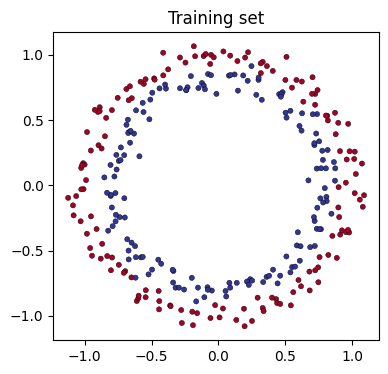

In [ ]:
train_X, train_Y, test_X, test_Y = load_circles()
print("train_X", tuple(train_X.shape), "| train_Y", tuple(train_Y.shape), "| test_X", tuple(test_X.shape))
plt.figure(figsize=(4.2, 4))
plt.scatter(train_X[:, 0], train_X[:, 1], c=train_Y.flatten(), s=14, cmap=plt.cm.RdYlBu, edgecolors="k", linewidths=0.3)
plt.title("Training set"); plt.show()

### 1.2 The model, by hand
`model` trains the 3-layer network `[2, 10, 5, 1]` with batch gradient descent. The only thing that changes between experiments is the **initialization**: `"zeros"`, `"random"` or `"he"`. The three functions are defined just after.

In [ ]:
def model(X, Y, initialization="he", lr=0.01, num_iters=15000, print_every=100):
    layer_dims = [X.shape[1], 10, 5, 1]
    if initialization == "zeros":
        params = initialize_parameters_zeros(layer_dims)
    elif initialization == "random":
        params = initialize_parameters_random(layer_dims)
    elif initialization == "he":
        params = initialize_parameters_he(layer_dims)
    costs = []
    for i in range(num_iters):
        A3, cache = forward_propagation(X, params)
        cost = compute_cost(A3, Y)
        grads = backward_propagation(X, Y, params, cache)
        params = update_parameters(params, grads, lr)
        if print_every and i % print_every == 0:
            costs.append(cost.item())
            if i % (5 * print_every) == 0:
                print(f"Cost after iteration {i}: {cost.item():.4f}")
    return params, costs

def show(params, costs, title):
    print(f"train accuracy {accuracy(logits_by_hand(params), train_X, train_Y):.1f}% | "
          f"test accuracy {accuracy(logits_by_hand(params), test_X, test_Y):.1f}%")
    plot_costs(costs, title, 1000)
    plt.figure(figsize=(4.2, 4)); plt.title(title)
    plot_decision_boundary(logits_by_hand(params), train_X, train_Y, lim=1.5); plt.show()

### 1.3 Zero initialization
All weights and biases start at 0. Shapes: $\mathbf{W}^{[l]}$ is $(n^{[l-1]}, n^{[l]})$ and $\mathbf{b}^{[l]}$ is $(1, n^{[l]})$.

In [ ]:
def initialize_parameters_zeros(layer_dims):
    params = {}
    for l in range(1, len(layer_dims)):
        params[f"W{l}"] = torch.zeros(layer_dims[l - 1], layer_dims[l])
        params[f"b{l}"] = torch.zeros(1, layer_dims[l])
    return params

for k, v in initialize_parameters_zeros([3, 2, 1]).items():
    print(k, "=", v.tolist())

W1 = [[0.0, 0.0], [0.0, 0.0], [0.0, 0.0]]
b1 = [[0.0, 0.0]]
W2 = [[0.0], [0.0]]
b2 = [[0.0]]


In [ ]:
params_zeros, costs_zeros = model(train_X, train_Y, initialization="zeros")

Cost after iteration 0: 0.6931
Cost after iteration 500: 0.6931
Cost after iteration 1000: 0.6931
Cost after iteration 1500: 0.6931
Cost after iteration 2000: 0.6931
Cost after iteration 2500: 0.6931
Cost after iteration 3000: 0.6931
Cost after iteration 3500: 0.6931
Cost after iteration 4000: 0.6931
Cost after iteration 4500: 0.6931
Cost after iteration 5000: 0.6931
Cost after iteration 5500: 0.6931
Cost after iteration 6000: 0.6931
Cost after iteration 6500: 0.6931
Cost after iteration 7000: 0.6931
Cost after iteration 7500: 0.6931
Cost after iteration 8000: 0.6931
Cost after iteration 8500: 0.6931
Cost after iteration 9000: 0.6931
Cost after iteration 9500: 0.6931
Cost after iteration 10000: 0.6931
Cost after iteration 10500: 0.6931
Cost after iteration 11000: 0.6931
Cost after iteration 11500: 0.6931
Cost after iteration 12000: 0.6931
Cost after iteration 12500: 0.6931
Cost after iteration 13000: 0.6931
Cost after iteration 13500: 0.6931
Cost after iteration 14000: 0.6931
Cost afte

train accuracy 50.0% | test accuracy 50.0%


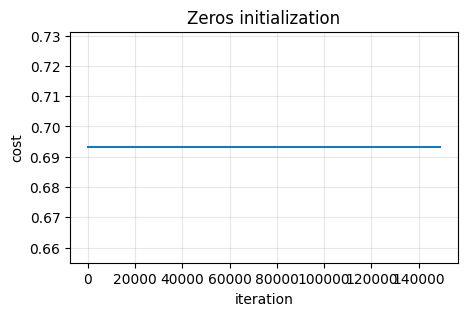

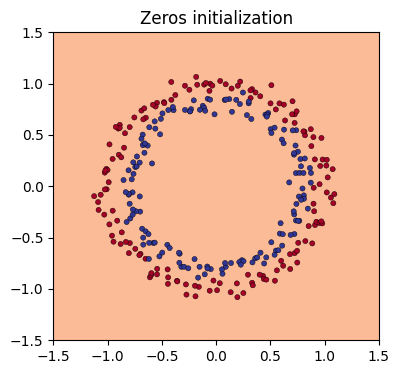

In [ ]:
show(params_zeros, costs_zeros, "Zeros initialization")

The cost never moves from $\log 2 = 0.6931$, and the model predicts the same class for every point: 50% accuracy.

**Why?** With all weights 0, every $\mathbf{Z}^{[l]}$ is 0, every ReLU outputs 0, and the sigmoid outputs $\sigma(0) = 0.5$ for every example. The gradients of $\mathbf{W}^{[2]}$ and $\mathbf{W}^{[3]}$ are products with activations that are all 0, and the error sent back through $\mathbf{W}^{[3]} = \mathbf{0}$ is 0: only $b^{[3]}$ could move, and it stays at 0 because the two classes are balanced. More generally, units that start equal compute the same thing and get the same update forever: the network cannot **break the symmetry**.

**Remember:** initialize $\mathbf{W}^{[l]}$ randomly. The biases $\mathbf{b}^{[l]}$ can start at 0.

### 1.4 Large random initialization
Random weights break the symmetry. Here we try **large** ones: `torch.randn(...) * 10`.

In [ ]:
def initialize_parameters_random(layer_dims, seed=3):
    torch.manual_seed(seed)
    params = {}
    for l in range(1, len(layer_dims)):
        params[f"W{l}"] = torch.randn(layer_dims[l - 1], layer_dims[l]) * 100
        params[f"b{l}"] = torch.zeros(1, layer_dims[l])
    return params

In [ ]:
params_random, costs_random = model(train_X, train_Y, initialization="random")

Cost after iteration 0: 7.3742
Cost after iteration 500: 1.8181
Cost after iteration 1000: 1.7327
Cost after iteration 1500: 1.2464
Cost after iteration 2000: 1.1651
Cost after iteration 2500: 1.0781
Cost after iteration 3000: 1.0705
Cost after iteration 3500: 1.3691
Cost after iteration 4000: 0.5498
Cost after iteration 4500: 1.2791
Cost after iteration 5000: 1.3066
Cost after iteration 5500: 1.0451
Cost after iteration 6000: 1.0127
Cost after iteration 6500: 0.6397
Cost after iteration 7000: 0.9313
Cost after iteration 7500: 0.9239
Cost after iteration 8000: 0.9287
Cost after iteration 8500: 1.1548
Cost after iteration 9000: 0.6871
Cost after iteration 9500: 0.9443
Cost after iteration 10000: 0.9592
Cost after iteration 10500: 0.9330
Cost after iteration 11000: 1.2031
Cost after iteration 11500: 0.6796
Cost after iteration 12000: 0.6169
Cost after iteration 12500: 0.9332
Cost after iteration 13000: 0.6135
Cost after iteration 13500: 0.9342
Cost after iteration 14000: 0.5570
Cost afte

train accuracy 68.3% | test accuracy 65.0%


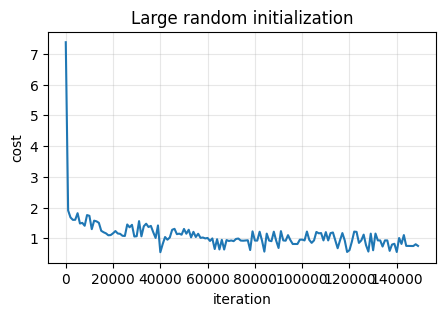

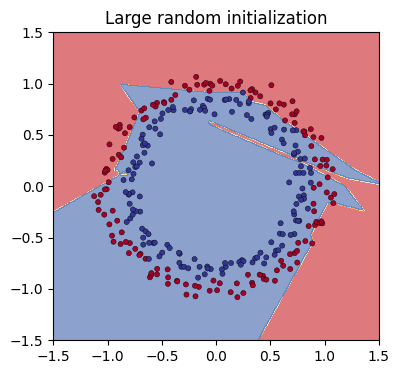

In [ ]:
show(params_random, costs_random, "Large random initialization")

The symmetry is broken and the model learns something, but slowly:

- The **first cost is very large.** With weights of size 10, $\mathbf{Z}^{[3]}$ is huge, the sigmoid outputs almost exactly 0 or 1, and every wrong prediction costs $-\log(\text{almost } 0)$. (Without the `clamp` in `compute_cost`, the cost would be `inf`.)
- Saturated outputs and huge activations make the optimization slow and unstable: the activations are close to **exploding**.

### 1.5 He initialization
For ReLU layers, He et al. (2015) scale the random weights by $\sqrt{2 / n^{[l-1]}}$ (lecture: "Weight initialization for deep networks").

In [ ]:
def initialize_parameters_he(layer_dims, seed=3):
    torch.manual_seed(seed)
    params = {}
    for l in range(1, len(layer_dims)):
        params[f"W{l}"] = torch.randn(layer_dims[l - 1], layer_dims[l]) * (2 / layer_dims[l - 1]) ** 0.5
        params[f"b{l}"] = torch.zeros(1, layer_dims[l])
    return params

In [ ]:
params_he, costs_he = model(train_X, train_Y, initialization="he")

Cost after iteration 0: 0.7258
Cost after iteration 500: 0.6867
Cost after iteration 1000: 0.6828
Cost after iteration 1500: 0.6795
Cost after iteration 2000: 0.6759
Cost after iteration 2500: 0.6707
Cost after iteration 3000: 0.6642
Cost after iteration 3500: 0.6563
Cost after iteration 4000: 0.6454
Cost after iteration 4500: 0.6322
Cost after iteration 5000: 0.6168
Cost after iteration 5500: 0.5978
Cost after iteration 6000: 0.5745
Cost after iteration 6500: 0.5488
Cost after iteration 7000: 0.5179
Cost after iteration 7500: 0.4846
Cost after iteration 8000: 0.4455
Cost after iteration 8500: 0.4060
Cost after iteration 9000: 0.3544
Cost after iteration 9500: 0.3080
Cost after iteration 10000: 0.2687
Cost after iteration 10500: 0.2371
Cost after iteration 11000: 0.2109
Cost after iteration 11500: 0.1892
Cost after iteration 12000: 0.1709
Cost after iteration 12500: 0.1558
Cost after iteration 13000: 0.1431
Cost after iteration 13500: 0.1327
Cost after iteration 14000: 0.1240
Cost afte

train accuracy 97.7% | test accuracy 94.0%


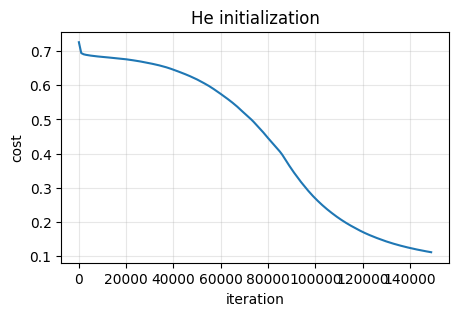

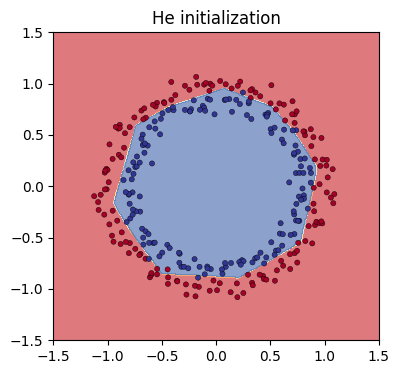

In [ ]:
show(params_he, costs_he, "He initialization")

### 1.6 Using PyTorch

| By hand | `torch.nn` |
|---|---|
| `torch.zeros(n_prev, n_l)` | `nn.init.zeros_(layer.weight)` |
| `torch.randn(n_prev, n_l) * 10` | `nn.init.normal_(layer.weight, mean=0.0, std=10.0)` |
| `torch.randn(n_prev, n_l) * (2 / n_prev) ** 0.5` | `nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")` |
| `torch.zeros(1, n_l)` | `nn.init.zeros_(layer.bias)` |

**One difference to remember:** `nn.Linear` stores its weight as `(n_out, n_in)`, the transpose of our $\mathbf{W}^{[l]}$, and computes `X @ weight.T + bias`. "Kaiming" is He's first name; by default it uses `n_in` (the "fan-in"), as in the lecture.

In [ ]:
class CircleModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1 = nn.Linear(in_features=2, out_features=10)
        self.layer_2 = nn.Linear(in_features=10, out_features=5)
        self.layer_3 = nn.Linear(in_features=5, out_features=1)
        self.relu = nn.ReLU()

    def forward(self, x):
        # LINEAR -> RELU -> LINEAR -> RELU -> LINEAR (logits)
        return self.layer_3(self.relu(self.layer_2(self.relu(self.layer_1(x)))))

def init_weights(model, method, seed=3):
    torch.manual_seed(seed)
    for layer in model.modules():
        if isinstance(layer, nn.Linear):
            if method == "zeros":
                nn.init.zeros_(layer.weight)
            elif method == "random":
                nn.init.normal_(layer.weight, mean=0.0, std=10.0)
            elif method == "he":
                nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
            nn.init.zeros_(layer.bias)
    return model

model_0 = init_weights(CircleModel(), "he").to(device)
print(model_0)
print("layer_1.weight:", tuple(model_0.layer_1.weight.shape), "= (n_out, n_in) | std",
      round(model_0.layer_1.weight.std().item(), 3), "| sqrt(2 / n_in) =", round((2 / 2) ** 0.5, 3))

CircleModel(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=5, bias=True)
  (layer_3): Linear(in_features=5, out_features=1, bias=True)
  (relu): ReLU()
)
layer_1.weight: (10, 2) = (n_out, n_in) | std 0.676 | sqrt(2 / n_in) = 1.0


In [ ]:
check_model = CircleModel()
p = initialize_parameters_he([2, 10, 5, 1])
with torch.no_grad():
    for l, layer in zip([1, 2, 3], [check_model.layer_1, check_model.layer_2, check_model.layer_3]):
        layer.weight.copy_(p[f"W{l}"].T)          # (n_in, n_out) -> (n_out, n_in)
        layer.bias.copy_(p[f"b{l}"].flatten())

A3_hand, cache = forward_propagation(train_X, p)
grads = backward_propagation(train_X, train_Y, p, cache)
loss = nn.BCEWithLogitsLoss()(check_model(train_X), train_Y)
loss.backward()                                    # autograd

print(f"sigmoid(logits) vs A3: max difference {(torch.sigmoid(check_model(train_X)) - A3_hand).abs().max().item():.1e}")
for l, layer in zip([1, 2, 3], [check_model.layer_1, check_model.layer_2, check_model.layer_3]):
    print(f"dW{l}: max difference {(layer.weight.grad.T - grads[f'dW{l}']).abs().max().item():.1e} | "
          f"db{l}: max difference {(layer.bias.grad - grads[f'db{l}'].flatten()).abs().max().item():.1e}")

sigmoid(logits) vs A3: max difference 0.0e+00
dW1: max difference 7.5e-09 | db1: max difference 3.7e-09
dW2: max difference 3.0e-08 | db2: max difference 3.7e-09
dW3: max difference 1.9e-09 | db3: max difference 0.0e+00


In [ ]:
def train_and_test(model, loss_fn, optimizer, X_train, y_train, X_test, y_test, epochs, print_every=None):
    X_train, y_train = X_train.to(device), y_train.to(device)
    X_test, y_test = X_test.to(device), y_test.to(device)
    for epoch in range(epochs):
        ### Training
        model.train()
        y_logits = model(X_train)                       # 1. forward pass (logits)
        y_pred = torch.round(torch.sigmoid(y_logits))   #    logits -> probabilities -> labels
        loss = loss_fn(y_logits, y_train)               # 2. loss
        acc = accuracy_fn(y_true=y_train, y_pred=y_pred)
        optimizer.zero_grad()                           # 3. zero the gradients
        loss.backward()                                 # 4. backpropagation
        optimizer.step()                                # 5. gradient descent step

        ### Testing
        model.eval()
        with torch.inference_mode():
            test_logits = model(X_test)
            test_pred = torch.round(torch.sigmoid(test_logits))
            test_loss = loss_fn(test_logits, y_test)
            test_acc = accuracy_fn(y_true=y_test, y_pred=test_pred)

        if print_every and epoch % print_every == 0:
            print(f"Epoch: {epoch:5d} | Loss: {loss:.5f}, Accuracy: {acc:.2f}% | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%")
    return model

In [ ]:
torch.manual_seed(42)
model_0 = init_weights(CircleModel(), "he").to(device)
loss_fn = nn.BCEWithLogitsLoss()                                 # sigmoid + binary cross-entropy
optimizer = torch.optim.SGD(params=model_0.parameters(), lr=0.01)
model_0 = train_and_test(model_0, loss_fn, optimizer, train_X, train_Y, test_X, test_Y, epochs=15000, print_every=100)

Epoch:     0 | Loss: 0.69057, Accuracy: 50.00% | Test loss: 0.69148, Test acc: 50.00%
Epoch:   100 | Loss: 0.68471, Accuracy: 51.67% | Test loss: 0.68563, Test acc: 50.00%
Epoch:   200 | Loss: 0.68217, Accuracy: 51.67% | Test loss: 0.68317, Test acc: 50.00%
Epoch:   300 | Loss: 0.68055, Accuracy: 52.33% | Test loss: 0.68171, Test acc: 52.00%
Epoch:   400 | Loss: 0.67924, Accuracy: 55.33% | Test loss: 0.68061, Test acc: 54.00%
Epoch:   500 | Loss: 0.67802, Accuracy: 55.33% | Test loss: 0.67959, Test acc: 54.00%
Epoch:   600 | Loss: 0.67683, Accuracy: 56.67% | Test loss: 0.67859, Test acc: 57.00%
Epoch:   700 | Loss: 0.67562, Accuracy: 57.33% | Test loss: 0.67753, Test acc: 58.00%
Epoch:   800 | Loss: 0.67436, Accuracy: 57.33% | Test loss: 0.67642, Test acc: 61.00%
Epoch:   900 | Loss: 0.67305, Accuracy: 58.00% | Test loss: 0.67530, Test acc: 60.00%
Epoch:  1000 | Loss: 0.67164, Accuracy: 58.67% | Test loss: 0.67409, Test acc: 60.00%
Epoch:  1100 | Loss: 0.67021, Accuracy: 59.00% | Test 

initialization      train     test
zeros               50.0%    50.0%
random              79.0%    76.0%
he                  98.7%    93.0%
default             97.3%    92.0%


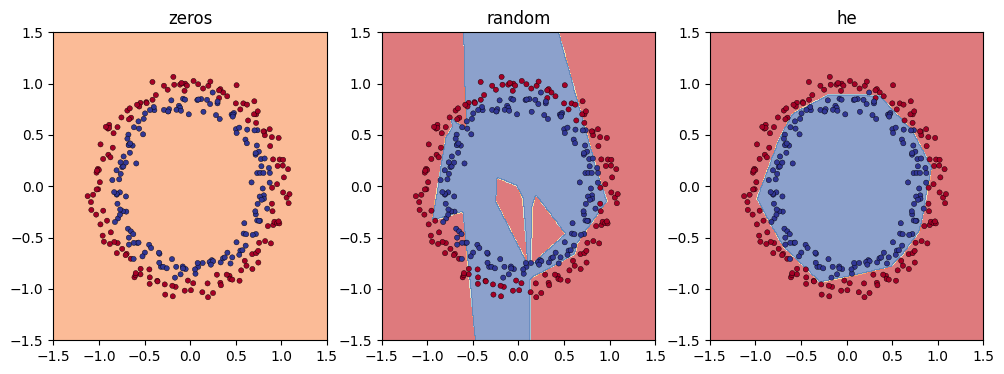

In [ ]:
results_init = {}
for method in ["zeros", "random", "he", "default"]:
    torch.manual_seed(3)
    m = CircleModel()                          # PyTorch's default initialization
    if method != "default":
        init_weights(m, method)
    m = m.to(device)
    opt = torch.optim.SGD(m.parameters(), lr=0.01)
    train_and_test(m, nn.BCEWithLogitsLoss(), opt, train_X, train_Y, test_X, test_Y, epochs=15000)
    results_init[method] = (accuracy(m, train_X, train_Y), accuracy(m, test_X, test_Y))

print(f"{'initialization':16s} {'train':>8s} {'test':>8s}")
for method, (tr, te) in results_init.items():
    print(f"{method:16s} {tr:7.1f}% {te:7.1f}%")

plt.figure(figsize=(12, 4))
for k, method in enumerate(["zeros", "random", "he"]):
    torch.manual_seed(3)
    m = init_weights(CircleModel(), method).to(device)
    train_and_test(m, nn.BCEWithLogitsLoss(), torch.optim.SGD(m.parameters(), lr=0.01), train_X, train_Y, test_X, test_Y, epochs=15000)
    plt.subplot(1, 3, k + 1); plt.title(method); plot_decision_boundary(m, train_X, train_Y, lim=1.5)
plt.show()

**What to remember from Part 1**
- Different initializations give very different results with the same network and the same training.
- Random weights break the symmetry; weights that are too large saturate the output and slow down learning.
- For ReLU networks, use He initialization: `nn.init.kaiming_normal_(w, nonlinearity="relu")`.

---
## 2 · Regularization

### 2.1 The data
A noisy 2-D dataset: 211 training points and 200 test points. The true boundary is a gentle curve, but the training labels contain mistakes: about 6% random errors, plus a few small **pockets** of wrong labels (for example, a region labeled by a careless annotator). The test labels contain only the random errors. A network that fits the pockets will generalize badly.

In [ ]:
def make_noisy_2d(m, seed, pockets=()):
    rng = np.random.default_rng(seed)
    X = rng.uniform(-1, 1, (m, 2))                                  # uniform in [-1, 1]^2
    Y = (X[:, 1] > 0.35 * np.sin(2.2 * X[:, 0]) - 0.1 * X[:, 0]).astype(float)
    flip = rng.random(m) < 0.06                                     # random label errors
    for cx, cy, r in pockets:                                       # pockets of wrong labels
        inside = (X[:, 0] - cx) ** 2 + (X[:, 1] - cy) ** 2 < r ** 2
        flip |= inside & (rng.random(m) < 0.7)
    Y[flip] = 1 - Y[flip]
    return torch.tensor(X, dtype=torch.float32), torch.tensor(Y, dtype=torch.float32).reshape(-1, 1)

train (211, 2) | test (200, 2) | fraction of class 1: 0.5


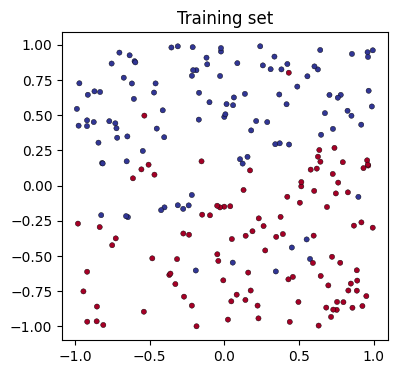

In [ ]:
POCKETS = [(-0.55, 0.05, 0.12), (0.1, 0.45, 0.10), (0.5, -0.45, 0.12), (-0.2, -0.55, 0.10)]
reg_train_X, reg_train_Y = make_noisy_2d(211, seed=0, pockets=POCKETS)
reg_test_X, reg_test_Y = make_noisy_2d(200, seed=1)
print("train", tuple(reg_train_X.shape), "| test", tuple(reg_test_X.shape), "| fraction of class 1:", round(reg_train_Y.mean().item(), 2))
plt.figure(figsize=(4.2, 4))
plt.scatter(reg_train_X[:, 0], reg_train_X[:, 1], c=reg_train_Y.flatten(), s=14, cmap=plt.cm.RdYlBu, edgecolors="k", linewidths=0.3)
plt.title("Training set"); plt.show()

### 2.2 The baseline model, by hand
The network is `[2, 20, 3, 1]`, initialized with $\sqrt{1/n^{[l-1]}}$ and trained for 30,000 iterations with $\alpha = 0.3$. `model_reg` can run in three modes:
- no regularization: `lambd = 0`, `keep_prob = 1`;
- **L2 regularization**: `lambd > 0` (we write `lambd` because `lambda` is a Python keyword);
- **dropout**: `keep_prob < 1`.

The L2 and dropout functions it calls are written in 2.3 and 2.4.

Cost after iteration 0: 0.7019
Cost after iteration 1000: 0.2248
Cost after iteration 2000: 0.2015
Cost after iteration 3000: 0.1924
Cost after iteration 4000: 0.1659
Cost after iteration 5000: 0.1523
Cost after iteration 6000: 0.1447
Cost after iteration 7000: 0.1435
Cost after iteration 8000: 0.1337
Cost after iteration 9000: 0.1310
Cost after iteration 10000: 0.1380
Cost after iteration 11000: 0.1298
Cost after iteration 12000: 0.1247
Cost after iteration 13000: 0.1217
Cost after iteration 14000: 0.1181
Cost after iteration 15000: 0.1123
Cost after iteration 16000: 0.1021
Cost after iteration 17000: 0.1512
Cost after iteration 18000: 0.0802
Cost after iteration 19000: 0.1786
Cost after iteration 20000: 0.0629
Cost after iteration 21000: 0.0906
Cost after iteration 22000: 0.0693
Cost after iteration 23000: 0.0529
Cost after iteration 24000: 0.0493
Cost after iteration 25000: 0.0583
Cost after iteration 26000: 0.0691
Cost after iteration 27000: 0.1152
Cost after iteration 28000: 0.037

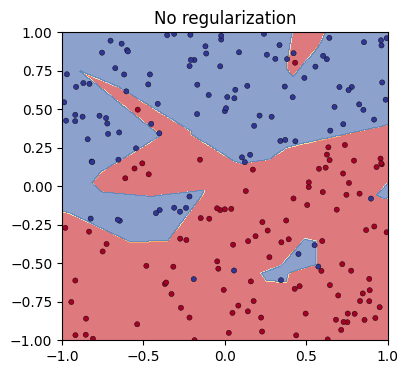

In [ ]:
def initialize_parameters(layer_dims, seed=3):
    torch.manual_seed(seed)
    params = {}
    for l in range(1, len(layer_dims)):
        params[f"W{l}"] = torch.randn(layer_dims[l - 1], layer_dims[l]) / layer_dims[l - 1] ** 0.5
        params[f"b{l}"] = torch.zeros(1, layer_dims[l])
    return params

def model_reg(X, Y, lr=0.3, num_iters=30000, lambd=0.0, keep_prob=1.0, print_every=1000, seed=1):
    params = initialize_parameters([X.shape[1], 20, 3, 1])
    gen = torch.Generator().manual_seed(seed)          # random masks for dropout
    for i in range(num_iters):
        if keep_prob == 1:
            A3, cache = forward_propagation(X, params)
        else:
            A3, cache = forward_propagation_with_dropout(X, params, keep_prob, gen)
        if lambd == 0:
            cost = compute_cost(A3, Y)
        else:
            cost = compute_cost_with_regularization(A3, Y, params, lambd)
        if lambd == 0 and keep_prob == 1:
            grads = backward_propagation(X, Y, params, cache)
        elif lambd != 0:
            grads = backward_propagation_with_regularization(X, Y, params, cache, lambd)
        else:
            grads = backward_propagation_with_dropout(X, Y, params, cache, keep_prob)
        params = update_parameters(params, grads, lr)
        if print_every and i % print_every == 0:
            print(f"Cost after iteration {i}: {cost.item():.4f}")
    return params

def report(name, model):
    tr = accuracy(model, reg_train_X, reg_train_Y)
    te = accuracy(model, reg_test_X, reg_test_Y)
    print(f"{name}: train accuracy {tr:.1f}% | test accuracy {te:.1f}%")
    return tr, te

def plot_reg(model, title):
    plt.figure(figsize=(4.2, 4)); plt.title(title)
    plot_decision_boundary(model, reg_train_X, reg_train_Y, lim=1.0); plt.show()

results_reg = {}
params_base = model_reg(reg_train_X, reg_train_Y)
results_reg["no regularization"] = report("no regularization", logits_by_hand(params_base))
plot_reg(logits_by_hand(params_base), "No regularization")

This is the **baseline**. Compare the training and the test accuracy, and look at the boundary: it bends around the pockets of wrong labels. The model is **overfitting** (high variance).

### 2.3 L2 regularization, by hand
The cost gets a penalty on the size of the weights (lecture: "L2 regularization: neural network"):
$$J_{\text{regularized}} = \underbrace{-\frac{1}{m}\sum_{i=1}^{m}\Big(y^{(i)}\log a^{[3](i)} + (1-y^{(i)})\log\big(1-a^{[3](i)}\big)\Big)}_{\text{cross-entropy cost}} + \underbrace{\frac{\lambda}{2m}\sum_{l=1}^{3}\lVert\mathbf{W}^{[l]}\rVert_F^2}_{\text{L2 cost}}$$
and, because the cost changed, every weight gradient gets an extra term: $d\mathbf{W}^{[l]} = (\text{from backprop}) + \frac{\lambda}{m}\mathbf{W}^{[l]}$. The biases are not regularized.

Cost after iteration 0: 0.7342
Cost after iteration 1000: 0.2991
Cost after iteration 2000: 0.2953
Cost after iteration 3000: 0.2931
Cost after iteration 4000: 0.2918
Cost after iteration 5000: 0.2906
Cost after iteration 6000: 0.2894
Cost after iteration 7000: 0.2889
Cost after iteration 8000: 0.2883
Cost after iteration 9000: 0.2881
Cost after iteration 10000: 0.2880
Cost after iteration 11000: 0.2879
Cost after iteration 12000: 0.2880
Cost after iteration 13000: 0.2879
Cost after iteration 14000: 0.2879
Cost after iteration 15000: 0.2879
Cost after iteration 16000: 0.2878
Cost after iteration 17000: 0.2878
Cost after iteration 18000: 0.2878
Cost after iteration 19000: 0.2879
Cost after iteration 20000: 0.2878
Cost after iteration 21000: 0.2878
Cost after iteration 22000: 0.2882
Cost after iteration 23000: 0.2878
Cost after iteration 24000: 0.2878
Cost after iteration 25000: 0.2877
Cost after iteration 26000: 0.2878
Cost after iteration 27000: 0.2877
Cost after iteration 28000: 0.288

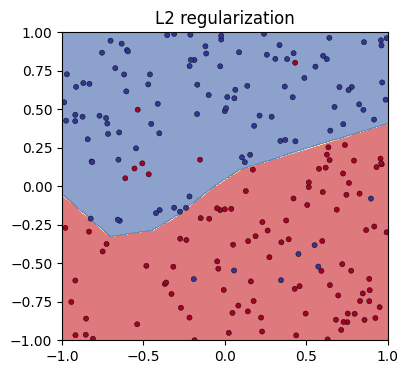

In [ ]:
def compute_cost_with_regularization(A3, Y, params, lambd):
    m = Y.shape[0]
    cross_entropy_cost = compute_cost(A3, Y)
    L2_cost = lambd / (2 * m) * sum((params[f"W{l}"] ** 2).sum() for l in [1, 2, 3])
    return cross_entropy_cost + L2_cost

def backward_propagation_with_regularization(X, Y, params, cache, lambd):
    m = X.shape[0]
    grads = backward_propagation(X, Y, params, cache)     # the usual gradients
    for l in [1, 2, 3]:
        grads[f"dW{l}"] = grads[f"dW{l}"] + lambd / m * params[f"W{l}"]
    return grads

params_L2 = model_reg(reg_train_X, reg_train_Y, lambd=0.7)
results_reg["L2, lambda = 0.7"] = report("L2, lambda = 0.7", logits_by_hand(params_L2))
plot_reg(logits_by_hand(params_L2), "L2 regularization")

Compare with the baseline: the training accuracy should go **down** and the test accuracy **up**, and the boundary should no longer bend around the pockets. Smaller weights give a simpler, smoother function.

`backward_propagation_with_regularization` reuses `backward_propagation` and only adds $\frac{\lambda}{m}\mathbf{W}^{[l]}$: the regularization changes nothing else.

### 2.4 Dropout, by hand
Inverted dropout on the two hidden layers (lecture: "Dropout regularization"). For layer 1, at **every** iteration:
1. draw a mask `D1` of the same shape as `A1`, $(m, n^{[1]})$, with 1 with probability `keep_prob` and 0 otherwise;
2. `A1 = A1 * D1`: shut down the dropped units;
3. `A1 = A1 / keep_prob`: keep the expected value of `A1` unchanged.

In the backward pass, apply the **same** mask and the same scaling to `dA1`. Same for layer 2. No dropout on the input or the output layer.

Cost after iteration 0: 0.7146
Cost after iteration 1000: 0.3121
Cost after iteration 2000: 0.2387
Cost after iteration 3000: 0.2588
Cost after iteration 4000: 0.2644
Cost after iteration 5000: 0.2714
Cost after iteration 6000: 0.2174
Cost after iteration 7000: 0.2323
Cost after iteration 8000: 0.1942
Cost after iteration 9000: 0.2002
Cost after iteration 10000: 0.2032
Cost after iteration 11000: 0.2299
Cost after iteration 12000: 0.2047
Cost after iteration 13000: 0.2782
Cost after iteration 14000: 0.2127
Cost after iteration 15000: 0.1875
Cost after iteration 16000: 0.1976
Cost after iteration 17000: 0.2346
Cost after iteration 18000: 0.2299
Cost after iteration 19000: 0.1991
Cost after iteration 20000: 0.1904
Cost after iteration 21000: 0.1669
Cost after iteration 22000: 0.2021
Cost after iteration 23000: 0.1688
Cost after iteration 24000: 0.1826
Cost after iteration 25000: 0.2579
Cost after iteration 26000: 0.2124
Cost after iteration 27000: 0.2197
Cost after iteration 28000: 0.185

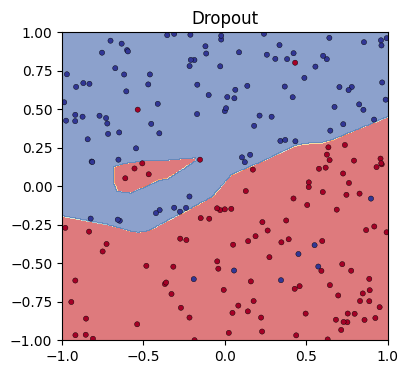

In [ ]:
def forward_propagation_with_dropout(X, params, keep_prob, gen):
    Z1 = X @ params["W1"] + params["b1"]
    A1 = torch.relu(Z1)
    D1 = (torch.rand(A1.shape, generator=gen) < keep_prob).float()    # step 1
    A1 = A1 * D1                                                      # step 2
    A1 = A1 / keep_prob                                               # step 3
    Z2 = A1 @ params["W2"] + params["b2"]
    A2 = torch.relu(Z2)
    D2 = (torch.rand(A2.shape, generator=gen) < keep_prob).float()
    A2 = A2 * D2 / keep_prob
    Z3 = A2 @ params["W3"] + params["b3"]
    A3 = torch.sigmoid(Z3)
    cache = (Z1, D1, A1, Z2, D2, A2, Z3, A3)
    return A3, cache

def backward_propagation_with_dropout(X, Y, params, cache, keep_prob):
    m = X.shape[0]
    Z1, D1, A1, Z2, D2, A2, Z3, A3 = cache
    dZ3 = A3 - Y
    dW3 = A2.T @ dZ3 / m
    db3 = dZ3.sum(dim=0, keepdim=True) / m
    dA2 = dZ3 @ params["W3"].T
    dA2 = dA2 * D2 / keep_prob                 # same mask, same scaling
    dZ2 = dA2 * (Z2 > 0).float()
    dW2 = A1.T @ dZ2 / m
    db2 = dZ2.sum(dim=0, keepdim=True) / m
    dA1 = dZ2 @ params["W2"].T
    dA1 = dA1 * D1 / keep_prob
    dZ1 = dA1 * (Z1 > 0).float()
    dW1 = X.T @ dZ1 / m
    db1 = dZ1.sum(dim=0, keepdim=True) / m
    return {"dW1": dW1, "db1": db1, "dW2": dW2, "db2": db2, "dW3": dW3, "db3": db3}

params_drop = model_reg(reg_train_X, reg_train_Y, keep_prob=0.86)
results_reg["dropout, keep_prob = 0.86"] = report("dropout, keep_prob = 0.86", logits_by_hand(params_drop))
plot_reg(logits_by_hand(params_drop), "Dropout")

### 2.5 Using PyTorch
| By hand | PyTorch |
|---|---|
| `compute_cost_with_regularization` and $+\frac{\lambda}{m}\mathbf{W}^{[l]}$ in backprop | `weight_decay=λ/m` in the optimizer |
| masks `D1`, `D2`, divide by `keep_prob` | `nn.Dropout(p=1 - keep_prob)` after each hidden ReLU |
| no dropout at test time | `model.eval()` (and `model.train()` to go back) |

Two details:
- **`p` in `nn.Dropout` is the probability of *dropping* a unit**, so `p = 1 - keep_prob`.
- `weight_decay` applies to every parameter it is given. To regularize only the weights, as in the lecture, give the optimizer two **parameter groups**.

In [ ]:
class RegModel(nn.Module):
    def __init__(self, keep_prob=1.0):
        super().__init__()
        self.layer_1 = nn.Linear(2, 20)
        self.layer_2 = nn.Linear(20, 3)
        self.layer_3 = nn.Linear(3, 1)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(p=1 - keep_prob)      # p = probability of DROPPING a unit

    def forward(self, x):
        x = self.dropout(self.relu(self.layer_1(x)))
        x = self.dropout(self.relu(self.layer_2(x)))
        return self.layer_3(x)                          # logits

def make_optimizer(model, lr, lambd, m):
    weights = [p for name, p in model.named_parameters() if name.endswith("weight")]
    biases = [p for name, p in model.named_parameters() if name.endswith("bias")]
    return torch.optim.SGD([{"params": weights, "weight_decay": lambd / m},
                            {"params": biases, "weight_decay": 0.0}], lr=lr)

print(RegModel(keep_prob=0.86))

RegModel(
  (layer_1): Linear(in_features=2, out_features=20, bias=True)
  (layer_2): Linear(in_features=20, out_features=3, bias=True)
  (layer_3): Linear(in_features=3, out_features=1, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.14, inplace=False)
)


**Check 1: `weight_decay` does exactly what our L2 code does.** One step with `weight_decay=λ/m` versus one step with the penalty written in the cost:

In [ ]:
lambd, m = 0.7, reg_train_X.shape[0]
torch.manual_seed(0); model_a = RegModel()
torch.manual_seed(0); model_b = RegModel()

# (a) weight_decay in the optimizer
opt_a = make_optimizer(model_a, lr=0.3, lambd=lambd, m=m)
loss_a = nn.BCEWithLogitsLoss()(model_a(reg_train_X), reg_train_Y)
opt_a.zero_grad(); loss_a.backward(); opt_a.step()

# (b) the L2 penalty written in the cost, plain SGD
opt_b = torch.optim.SGD(model_b.parameters(), lr=0.3)
penalty = lambd / (2 * m) * sum((layer.weight ** 2).sum() for layer in [model_b.layer_1, model_b.layer_2, model_b.layer_3])
loss_b = nn.BCEWithLogitsLoss()(model_b(reg_train_X), reg_train_Y) + penalty
opt_b.zero_grad(); loss_b.backward(); opt_b.step()

diff = max((pa - pb).abs().max().item() for pa, pb in zip(model_a.parameters(), model_b.parameters()))
print(f"max difference between the parameters after one step: {diff:.1e}")

max difference between the parameters after one step: 0.0e+00


Identical up to rounding. Note that `loss_a` does **not** contain the penalty: with `weight_decay`, the regularization lives in the update rule, not in the printed loss.

**Check 2: `nn.Dropout` is inverted dropout.** On a tensor of ones, in training mode and in evaluation mode:

In [ ]:
torch.manual_seed(0)
drop = nn.Dropout(p=0.5)
drop.train()
print("train mode:", drop(torch.ones(10)))
drop.eval()
print("eval mode: ", drop(torch.ones(10)))

train mode: tensor([0., 0., 2., 0., 0., 0., 2., 2., 0., 2.])
eval mode:  tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])


In training mode, about half of the values are set to 0 and the others are divided by `keep_prob = 0.5`, i.e. multiplied by 2. In evaluation mode, `nn.Dropout` does nothing. This is why the loop calls `model.train()` before the training step and `model.eval()` before testing.

Finally, the three models of this part, trained with the same loop as in Part 1:

PyTorch | no regularization: train accuracy 96.7% | test accuracy 91.0%
PyTorch | L2, lambda = 0.7: train accuracy 91.9% | test accuracy 94.0%
PyTorch | dropout, keep_prob = 0.86: train accuracy 96.7% | test accuracy 89.5%


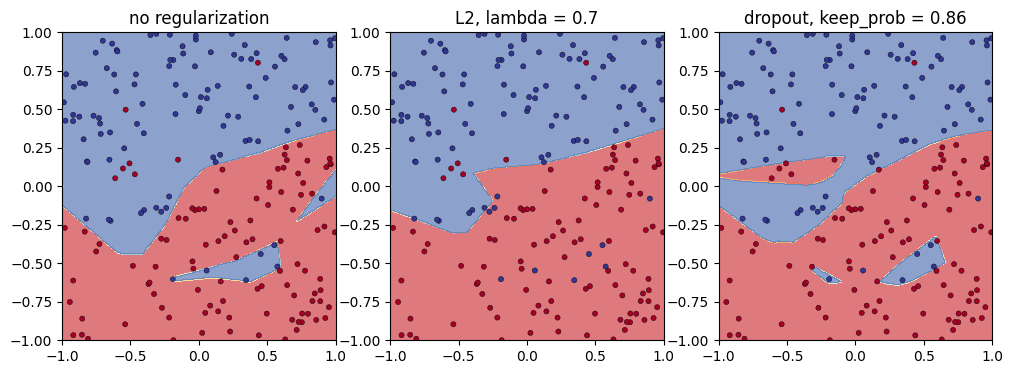

In [ ]:
def train_reg_model(lambd=0.0, keep_prob=1.0, lr=0.3, epochs=30000, seed=3, print_every=None):
    torch.manual_seed(seed)
    model = RegModel(keep_prob).to(device)
    optimizer = make_optimizer(model, lr, lambd, reg_train_X.shape[0])
    return train_and_test(model, nn.BCEWithLogitsLoss(), optimizer, reg_train_X, reg_train_Y,
                          reg_test_X, reg_test_Y, epochs=epochs, print_every=print_every)

results_nn = {}
models_nn = {}
for name, kw in [("no regularization", {}), ("L2, lambda = 0.7", {"lambd": 0.7}), ("dropout, keep_prob = 0.86", {"keep_prob": 0.86})]:
    models_nn[name] = train_reg_model(**kw)
    results_nn[name] = report(f"PyTorch | {name}", models_nn[name])

plt.figure(figsize=(12, 4))
for k, name in enumerate(models_nn):
    plt.subplot(1, 3, k + 1); plt.title(name); plot_decision_boundary(models_nn[name], reg_train_X, reg_train_Y, lim=1.0)
plt.show()

The numbers are not identical to the hand-written version (`nn.Linear` draws its random numbers differently, and the dropout masks differ), but they should lead to the same conclusions.

### 2.6 Conclusions

In [ ]:
print(f"{'model':28s} {'by hand':>18s} {'PyTorch':>18s}")
print(f"{'':28s} {'train':>8s} {'test':>8s}   {'train':>8s} {'test':>8s}")
for name in results_reg:
    (a, b), (c, d) = results_reg[name], results_nn[name]
    print(f"{name:28s} {a:7.1f}% {b:7.1f}%   {c:7.1f}% {d:7.1f}%")

model                                   by hand            PyTorch
                                train     test      train     test
no regularization               96.7%    85.0%      96.7%    91.0%
L2, lambda = 0.7                93.4%    95.0%      91.9%    94.0%
dropout, keep_prob = 0.86       95.3%    94.0%      96.7%    89.5%


**What to remember from Part 2**
- Regularization **lowers the training accuracy** and **raises the test accuracy**: it stops the network from fitting the noise.
- L2 adds $\frac{\lambda}{2m}\sum_l\lVert\mathbf{W}^{[l]}\rVert_F^2$ to the cost and $\frac{\lambda}{m}\mathbf{W}^{[l]}$ to each gradient; in PyTorch, `weight_decay=λ/m`.
- Dropout is used **only during training**, in the forward **and** the backward pass, with the division by `keep_prob`; in PyTorch, `nn.Dropout(p=1 - keep_prob)` with `model.train()` / `model.eval()`.
- $\lambda$ and `keep_prob` are hyperparameters, chosen on a dev set.

---
## ★ Assignment (to submit)

### Exercise 1 · The moons dataset
Make a binary classification dataset with scikit-learn's `make_moons()`: 1000 samples, `noise=0.07`, `random_state=42`. Turn it into PyTorch tensors (`float32`; labels of shape $(m, 1)$) and split it into 80% training and 20% test data with `train_test_split(..., test_size=0.2, random_state=42)`. Plot the training set.

train_X (800, 2) | train_y (800, 1) | test_X (200, 2) | test_y (200, 1)


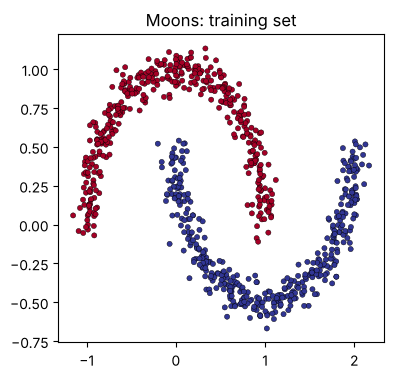

In [ ]:
# Exercise 1
X_moons, y_moons = make_moons(n_samples=1000, noise=0.07, random_state=42)
X_moons = torch.tensor(X_moons, dtype=torch.float32)
y_moons = torch.tensor(y_moons, dtype=torch.float32).reshape(-1, 1)

moons_train_X, moons_test_X, moons_train_y, moons_test_y = train_test_split(
    X_moons, y_moons, test_size=0.2, random_state=42)
print("train_X", tuple(moons_train_X.shape), "| train_y", tuple(moons_train_y.shape),
      "| test_X", tuple(moons_test_X.shape), "| test_y", tuple(moons_test_y.shape))

plt.figure(figsize=(4.2, 4))
plt.scatter(moons_train_X[:, 0], moons_train_X[:, 1], c=moons_train_y.flatten(), s=14,
            cmap=plt.cm.RdYlBu, edgecolors="k", linewidths=0.3)
plt.title("Moons: training set"); plt.show()

**Comment – Exercise 1 (moons dataset)**

- `make_moons` gives two interlocking half-circles: the classes **cannot be separated by a straight line**, so the model will need hidden layers with non-linear activations.
- Features are converted to `float32` (what `nn.Linear` expects) and labels are reshaped to `(m, 1)` so they match the single logit of the model and `BCEWithLogitsLoss`.
- The 80/20 split gives 800 training and 200 test points (shapes printed above). Using `random_state=42` makes the split reproducible.
- The plot shows the two moons with only a little overlap (`noise=0.07`), so a high accuracy is realistic.

### Exercise 2 · A model for the moons
Build a model by subclassing `nn.Module`, with non-linear activation functions, capable of fitting the moons. It should output **one logit**. Initialize every `nn.Linear` with **He initialization** and zero biases (Part 1.6). Print the model and its number of parameters.

In [ ]:
# Exercise 2
class MoonsModel(nn.Module):
    def __init__(self, hidden=16):
        super().__init__()
        self.layer_1 = nn.Linear(2, hidden)
        self.layer_2 = nn.Linear(hidden, hidden)
        self.layer_3 = nn.Linear(hidden, 1)
        self.relu = nn.ReLU()

    def forward(self, x):
        # LINEAR -> RELU -> LINEAR -> RELU -> LINEAR (one logit)
        return self.layer_3(self.relu(self.layer_2(self.relu(self.layer_1(x)))))

moons_model = init_weights(MoonsModel(), "he").to(device)     # He weights, zero biases (Part 1.6)
print(moons_model)
print("number of parameters:", sum(p.numel() for p in moons_model.parameters()))

MoonsModel(
  (layer_1): Linear(in_features=2, out_features=16, bias=True)
  (layer_2): Linear(in_features=16, out_features=16, bias=True)
  (layer_3): Linear(in_features=16, out_features=1, bias=True)
  (relu): ReLU()
)
number of parameters: 337


**Comment – Exercise 2 (model for the moons)**

- Architecture: `2 → 16 → 16 → 1`, with ReLU after each hidden layer and **no activation on the output**: the model returns one raw logit (the sigmoid is applied inside the loss, see Exercise 3).
- The ReLUs are what let the network bend the boundary around the moons; without them the model would just be a linear classifier.
- `init_weights(..., "he")` applies `kaiming_normal_` to the weights (suited to ReLU) and zeros to the biases, as in Part 1.6.
- Parameter count: $(2\times16+16) + (16\times16+16) + (16\times1+1) = 48 + 272 + 17 = 337$, which matches the printed value.

### Exercise 3 · Loss and optimizer
Set up a loss function for binary classification that works with **logits**, and an SGD optimizer (batch gradient descent). Explain in one sentence why `nn.BCEWithLogitsLoss` is preferred to `nn.Sigmoid()` + `nn.BCELoss()`.

In [ ]:
# Exercise 3
loss_fn_moons = nn.BCEWithLogitsLoss()                                     # takes logits: sigmoid + binary cross-entropy
optimizer_moons = torch.optim.SGD(moons_model.parameters(), lr=0.1)        # the whole training set at each step: batch gradient descent

**Why `nn.BCEWithLogitsLoss` and not `nn.Sigmoid()` + `nn.BCELoss()`?** It computes the sigmoid and the binary cross-entropy together in one numerically stable step, so it stays accurate when the sigmoid saturates (outputs exactly 0 or 1), where the two separate steps lose precision.

**Comment – Exercise 3 (loss and optimizer)**

- The task is binary classification with one logit, so `nn.BCEWithLogitsLoss` is the right loss: it expects **logits**, not probabilities.
- `torch.optim.SGD` with the **whole training set** in each step is batch gradient descent, exactly as in the by-hand code. A learning rate of 0.1 is large enough to make progress in 1000 epochs without diverging.
- Prediction at test time: `sigmoid(logit)` then rounding at 0.5 (equivalently, `logit > 0`).

### Exercise 4 · Training and testing loop
Write a training and testing loop (you may reuse `train_and_test` or write your own) and train the model until it reaches **more than 96% test accuracy**. Print the training and test loss and accuracy every 100 epochs. If you do not reach 96%, change the learning rate, the number of epochs or the number of hidden units, and explain what you changed.

In [ ]:
# Exercise 4
moons_model = train_and_test(moons_model, loss_fn_moons, optimizer_moons,
                             moons_train_X, moons_train_y, moons_test_X, moons_test_y,
                             epochs=1000, print_every=100)
print(f"train accuracy {accuracy(moons_model, moons_train_X, moons_train_y):.2f}% | "
      f"test accuracy {accuracy(moons_model, moons_test_X, moons_test_y):.2f}%")

Epoch:     0 | Loss: 0.80569, Accuracy: 34.88% | Test loss: 0.53228, Test acc: 72.00%
Epoch:   100 | Loss: 0.27666, Accuracy: 87.62% | Test loss: 0.27185, Test acc: 86.50%
Epoch:   200 | Loss: 0.24060, Accuracy: 87.50% | Test loss: 0.23677, Test acc: 87.00%
Epoch:   300 | Loss: 0.20175, Accuracy: 88.50% | Test loss: 0.19937, Test acc: 88.50%


Epoch:   400 | Loss: 0.16415, Accuracy: 93.25% | Test loss: 0.16088, Test acc: 94.00%
Epoch:   500 | Loss: 0.12693, Accuracy: 95.75% | Test loss: 0.12094, Test acc: 97.50%
Epoch:   600 | Loss: 0.09072, Accuracy: 97.75% | Test loss: 0.08255, Test acc: 98.00%


Epoch:   700 | Loss: 0.06134, Accuracy: 99.12% | Test loss: 0.05222, Test acc: 100.00%
Epoch:   800 | Loss: 0.04145, Accuracy: 99.50% | Test loss: 0.03322, Test acc: 100.00%
Epoch:   900 | Loss: 0.02928, Accuracy: 99.62% | Test loss: 0.02226, Test acc: 100.00%


train accuracy 99.75% | test accuracy 100.00%


**Exercise 4 note.** The first setting was enough (16 hidden units per layer, learning rate 0.1, 1000 epochs, test accuracy above 96%), so nothing had to be changed.

**Comment – Exercise 4 (training and testing loop)**

- Final result: **99.75% train / 100% test accuracy**, above the 96% target.
- The loss starts at about 0.81 (a bit above $\log 2 \approx 0.69$ because the random initial logits are not exactly 0) and decreases steadily. Accuracy stays around 87–88% for the first 300 epochs, then rises quickly once the network has learned to bend the boundary (95% at epoch 500, 99% at epoch 700).
- Train and test losses stay very close to each other, so there is **no overfitting**: the model is simple, the dataset is clean, and the test set is small (200 points, so one point = 0.5%).
- Test accuracy slightly above train accuracy is possible here: it only reflects which 200 points ended up in the test set, not better generalization.

### Exercise 5 · Decision boundaries
Plot the decision boundary of your trained model on the training set and on the test set, side by side, with `plot_decision_boundary`.

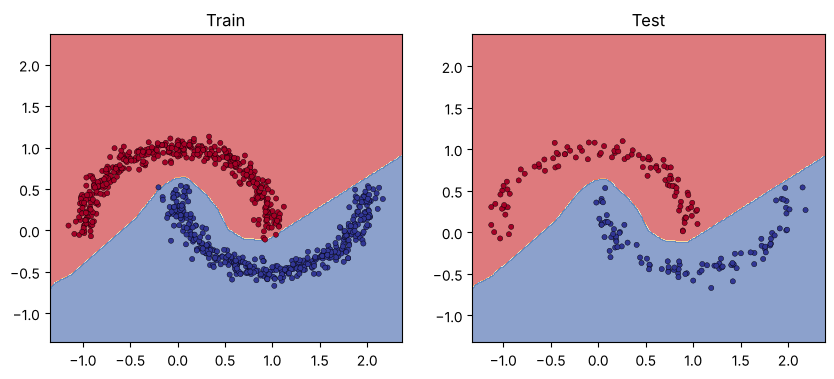

In [ ]:
# Exercise 5
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.title("Train")
plot_decision_boundary(moons_model, moons_train_X, moons_train_y)
plt.subplot(1, 2, 2); plt.title("Test")
plot_decision_boundary(moons_model, moons_test_X, moons_test_y)
plt.show()

**Comment – Exercise 5 (decision boundaries)**

- The boundary is a smooth curve that goes **between** the two moons: the upper moon is above it and the lower moon below, as the two clusters interlock.
- Train and test plots show the same boundary, and the test points are on the correct side. This agrees with the 100% test accuracy and confirms that the model generalizes.
- Far from the data (corners of the plot) the boundary becomes almost straight lines. This is normal for a ReLU network, which is piecewise linear, and it does not matter because there are no points there.

### Exercise 6 · Tanh in pure PyTorch
Write `tanh(z)` using only `torch.exp` and arithmetic: $\tanh(z) = \frac{e^{z} - e^{-z}}{e^{z} + e^{-z}}$. Compare it with `torch.tanh` on `torch.linspace(-5, 5, 101)` (print the maximum difference) and plot both.

*Optional:* what happens with your function for $z = 100$? Rewrite it as $\tanh(z) = 2\sigma(2z) - 1$ and explain why this version is safer.

max difference with torch.tanh: 1.1920928955078125e-07


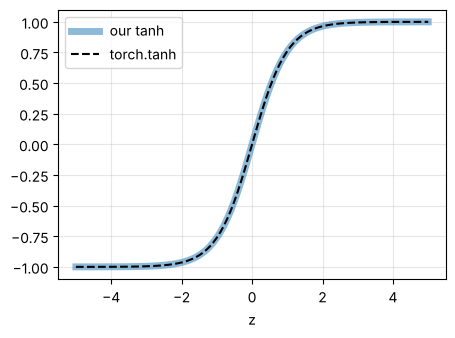

exp(100)            = inf
our tanh(100, -100) = tensor([nan, nan])
tanh_safe(100, -100) = tensor([ 1., -1.])
max difference of tanh_safe with torch.tanh on [-5, 5]: 1.1920928955078125e-07


In [ ]:
# Exercise 6
def tanh(z):
    return (torch.exp(z) - torch.exp(-z)) / (torch.exp(z) + torch.exp(-z))

z = torch.linspace(-5, 5, 101)
print("max difference with torch.tanh:", (tanh(z) - torch.tanh(z)).abs().max().item())

plt.figure(figsize=(5, 3.5))
plt.plot(z, tanh(z), label="our tanh", linewidth=5, alpha=0.5)
plt.plot(z, torch.tanh(z), "--", label="torch.tanh", color="k")
plt.xlabel("z"); plt.legend(); plt.grid(alpha=0.3); plt.show()

# Optional: very large |z|
def tanh_safe(z):
    return 2 * torch.sigmoid(2 * z) - 1

big = torch.tensor([100.0, -100.0])
print("exp(100)            =", torch.exp(torch.tensor(100.0)).item())
print("our tanh(100, -100) =", tanh(big))
print("tanh_safe(100, -100) =", tanh_safe(big))
print("max difference of tanh_safe with torch.tanh on [-5, 5]:", (tanh_safe(z) - torch.tanh(z)).abs().max().item())

**Optional: why is `tanh_safe` safer?** For $z = 100$, $e^{100} \approx 2.7 \times 10^{43}$ is larger than the largest `float32` number ($\approx 3.4 \times 10^{38}$), so `torch.exp` returns `inf` and the result is $\infty / \infty = $ `nan` (the same happens for $z = -100$). The version $2\sigma(2z) - 1$ never builds such a huge number: `torch.sigmoid` handles large inputs and simply returns 1 (or 0), so `tanh_safe(100)` is 1 and `tanh_safe(-100)` is -1.

**Comment – Exercise 6 (tanh in pure PyTorch)**

- Our `tanh` built from `torch.exp` matches `torch.tanh` up to about $1.2\times10^{-7}$, which is the `float32` rounding error. On the plot the two curves overlap exactly: an S-shaped curve with values between −1 and 1, equal to 0 at $z=0$.
- The simple formula is **numerically fragile** for large $|z|$: $e^{100}$ overflows `float32` and gives `inf`, so the result is `inf/inf = nan`.
- `tanh_safe(z) = 2σ(2z) − 1` is mathematically the same function (and has the same $10^{-7}$ error on $[-5, 5]$), but `torch.sigmoid` is implemented in a stable way, so it returns exactly 1 and −1 for $z = \pm100$. This is the same idea as using `BCEWithLogitsLoss` in Exercise 3: never build huge intermediate numbers.

### Exercise 7 · A multi-class problem: spirals
Create the 3-class spiral dataset of CS231n with the code below (300 points), turn it into tensors (`X` as `float32`, `y` as `long` of shape $(m,)$), and split it 80/20 with `random_state=42`.

Then:
- build a model capable of fitting the data; it outputs **3 logits** (one per class);
- use `nn.CrossEntropyLoss()` (softmax + cross-entropy, Lecture 2) and an optimizer (optional extension: `torch.optim.Adam`; you may have to try several learning rates);
- write a training and testing loop for the multi-class case (predicted class = `argmax` of the logits) and reach **more than 95% test accuracy**;
- plot the decision boundaries on the training and test sets with `plot_decision_boundary` (it handles several classes).

```python
# Code for creating a spiral dataset from CS231n
np.random.seed(42)
N = 100  # number of points per class
D = 2    # dimensionality
K = 3    # number of classes
X = np.zeros((N * K, D))           # data matrix (each row = single example)
y = np.zeros(N * K, dtype="uint8")  # class labels
for j in range(K):
    ix = range(N * j, N * (j + 1))
    r = np.linspace(0.0, 1, N)                                    # radius
    t = np.linspace(j * 4, (j + 1) * 4, N) + np.random.randn(N) * 0.2  # theta
    X[ix] = np.c_[r * np.sin(t), r * np.cos(t)]
    y[ix] = j
plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.Spectral)
plt.show()
```

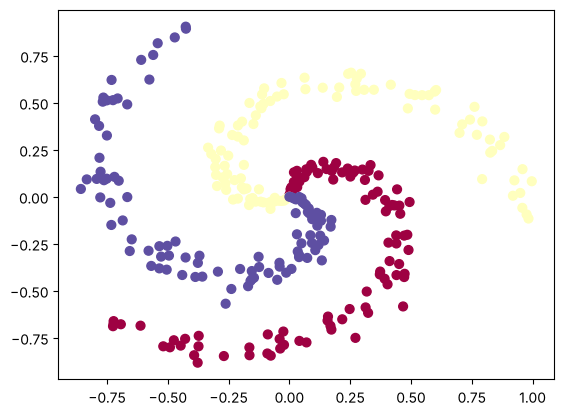

train (240, 2) (240,) | test (60, 2) (60,)
Epoch:     0 | Loss: 1.08269, Accuracy: 32.92% | Test loss: 1.02882, Test acc: 61.67%


Epoch:   100 | Loss: 0.03581, Accuracy: 99.17% | Test loss: 0.00854, Test acc: 100.00%


Epoch:   200 | Loss: 0.02164, Accuracy: 99.17% | Test loss: 0.00100, Test acc: 100.00%


Epoch:   300 | Loss: 0.01775, Accuracy: 99.17% | Test loss: 0.00025, Test acc: 100.00%


Epoch:   400 | Loss: 0.01624, Accuracy: 99.17% | Test loss: 0.00005, Test acc: 100.00%


Epoch:   500 | Loss: 0.01582, Accuracy: 99.17% | Test loss: 0.00002, Test acc: 100.00%


Epoch:   600 | Loss: 0.01468, Accuracy: 99.17% | Test loss: 0.00001, Test acc: 100.00%


Epoch:   700 | Loss: 0.01440, Accuracy: 99.17% | Test loss: 0.00001, Test acc: 100.00%


Epoch:   800 | Loss: 0.01437, Accuracy: 99.17% | Test loss: 0.00000, Test acc: 100.00%


Epoch:   900 | Loss: 0.01425, Accuracy: 99.17% | Test loss: 0.00000, Test acc: 100.00%


train accuracy 99.17% | test accuracy 100.00%


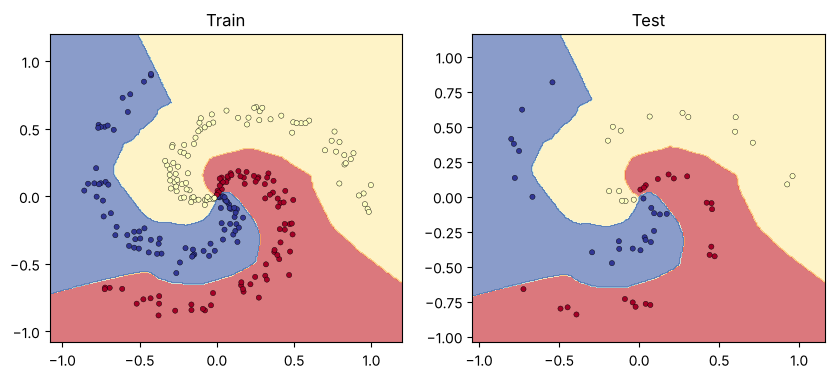

In [ ]:
# Exercise 7: data
# Code for creating a spiral dataset from CS231n
np.random.seed(42)
N = 100  # number of points per class
D = 2    # dimensionality
K = 3    # number of classes
X = np.zeros((N * K, D))           # data matrix (each row = single example)
y = np.zeros(N * K, dtype="uint8")  # class labels
for j in range(K):
    ix = range(N * j, N * (j + 1))
    r = np.linspace(0.0, 1, N)                                    # radius
    t = np.linspace(j * 4, (j + 1) * 4, N) + np.random.randn(N) * 0.2  # theta
    X[ix] = np.c_[r * np.sin(t), r * np.cos(t)]
    y[ix] = j
plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.Spectral)
plt.show()

# tensors (X float32, y long of shape (m,)) and 80/20 split
spiral_X = torch.tensor(X, dtype=torch.float32)
spiral_y = torch.tensor(y, dtype=torch.long)
spiral_train_X, spiral_test_X, spiral_train_y, spiral_test_y = train_test_split(
    spiral_X, spiral_y, test_size=0.2, random_state=42)
print("train", tuple(spiral_train_X.shape), tuple(spiral_train_y.shape),
      "| test", tuple(spiral_test_X.shape), tuple(spiral_test_y.shape))

# model: 2 -> hidden -> hidden -> 3 logits (p = dropout probability, 0 = no dropout)
class SpiralModel(nn.Module):
    def __init__(self, hidden=64, p=0.0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, hidden), nn.ReLU(), nn.Dropout(p),
            nn.Linear(hidden, hidden), nn.ReLU(), nn.Dropout(p),
            nn.Linear(hidden, 3))

    def forward(self, x):
        return self.net(x)

# loss, optimizer, training and testing loop
def train_and_test_multiclass(model, loss_fn, optimizer, X_train, y_train, X_test, y_test, epochs, print_every=None):
    X_train, y_train = X_train.to(device), y_train.to(device)
    X_test, y_test = X_test.to(device), y_test.to(device)
    for epoch in range(epochs):
        ### Training
        model.train()
        logits = model(X_train)                                  # (m, 3) logits
        loss = loss_fn(logits, y_train)                          # softmax + cross-entropy
        acc = accuracy_fn(y_true=y_train, y_pred=logits.argmax(dim=1))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        ### Testing
        model.eval()
        with torch.inference_mode():
            test_logits = model(X_test)
            test_loss = loss_fn(test_logits, y_test)
            test_acc = accuracy_fn(y_true=y_test, y_pred=test_logits.argmax(dim=1))
        if print_every and epoch % print_every == 0:
            print(f"Epoch: {epoch:5d} | Loss: {loss:.5f}, Accuracy: {acc:.2f}% | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%")
    return model

torch.manual_seed(0)
spiral_model = SpiralModel(hidden=64).to(device)
spiral_loss_fn = nn.CrossEntropyLoss()
spiral_optimizer = torch.optim.Adam(spiral_model.parameters(), lr=0.01)
spiral_model = train_and_test_multiclass(spiral_model, spiral_loss_fn, spiral_optimizer,
                                         spiral_train_X, spiral_train_y, spiral_test_X, spiral_test_y,
                                         epochs=1000, print_every=100)
print(f"train accuracy {accuracy(spiral_model, spiral_train_X, spiral_train_y):.2f}% | "
      f"test accuracy {accuracy(spiral_model, spiral_test_X, spiral_test_y):.2f}%")

# decision boundaries
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.title("Train")
plot_decision_boundary(spiral_model, spiral_train_X, spiral_train_y)
plt.subplot(1, 2, 2); plt.title("Test")
plot_decision_boundary(spiral_model, spiral_test_X, spiral_test_y)
plt.show()

**Comment – Exercise 7 (spirals, 3 classes)**

- Differences from the binary case: the model has **3 logits** (one per class), the loss is `nn.CrossEntropyLoss` (softmax + cross-entropy, so no softmax inside the model), the labels are `long` of shape `(m,)` and not `(m, 1)`, and the prediction is `argmax` of the logits.
- The three spirals are strongly intertwined, so a model with two hidden layers of 64 units is needed. **Adam** with `lr=0.01` converges much faster than plain SGD on this problem.
- Result: **99.17% train / 100% test accuracy**, above the 95% target. The training loss stops improving after about 400 epochs (≈0.014) and the test loss goes to almost 0: the model has essentially learned the spirals.
- The test set has only 60 points, so 100% test accuracy is a noisy estimate; the 99.17% on 240 training points (2 errors) is a bit more informative.

### Exercise 8 · Regularization on the spirals (TP3)
Train a **much larger** spiral model (for example two hidden layers of 128 units) for long enough that it overfits: training accuracy near 100%, and a visible gap with the test accuracy. Then train the same model with
- **L2 regularization** (`weight_decay` on the weights only, as in Part 2.5), and
- **dropout** (`nn.Dropout`),

keeping everything else equal. Report the training and test accuracy of the three models in a small table, plot the three decision boundaries, and answer in a markdown cell: which model would you choose, and why? Which set should be used to choose `weight_decay` and the dropout rate in a real project?

model                         train     test
no regularization             99.2%   100.0%
L2 (weight_decay=1e-3)        99.2%   100.0%
dropout (p=0.2)               99.2%   100.0%


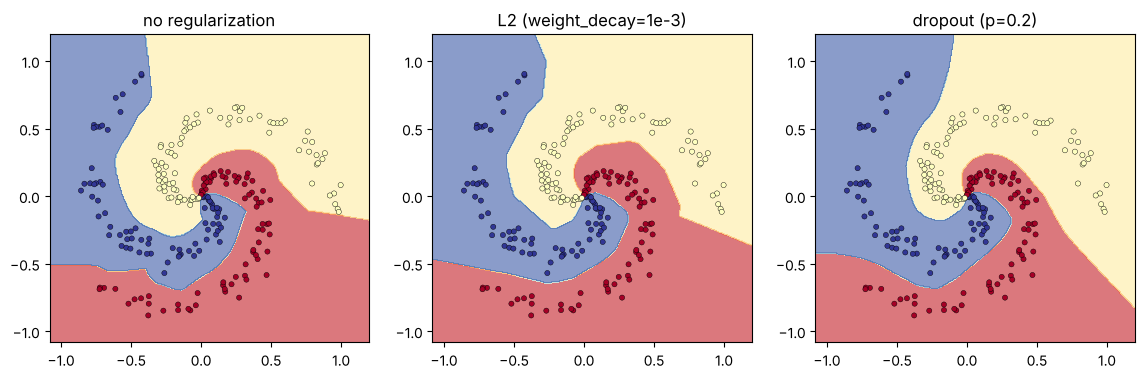

In [ ]:
# Exercise 8
# Same model (2 hidden layers of 128 units), same optimizer, same seed, same number of epochs: only the regularization changes.
def make_spiral_model(hidden=128, p=0.0, weight_decay=0.0, lr=0.01, seed=0):
    torch.manual_seed(seed)
    model = SpiralModel(hidden, p).to(device)
    weights = [q for n, q in model.named_parameters() if n.endswith("weight")]
    biases = [q for n, q in model.named_parameters() if n.endswith("bias")]
    optimizer = torch.optim.Adam([{"params": weights, "weight_decay": weight_decay},   # L2 on the weights only
                                  {"params": biases, "weight_decay": 0.0}], lr=lr)
    return model, optimizer

settings = {"no regularization": {},
            "L2 (weight_decay=1e-3)": {"weight_decay": 1e-3},
            "dropout (p=0.2)": {"p": 0.2}}

big_models, results_spiral = {}, {}
for name, kw in settings.items():
    model, optimizer = make_spiral_model(**kw)
    train_and_test_multiclass(model, nn.CrossEntropyLoss(), optimizer,
                              spiral_train_X, spiral_train_y, spiral_test_X, spiral_test_y, epochs=3000)
    big_models[name] = model
    results_spiral[name] = (accuracy(model, spiral_train_X, spiral_train_y),
                            accuracy(model, spiral_test_X, spiral_test_y))

print(f"{'model':26s} {'train':>8s} {'test':>8s}")
for name, (tr, te) in results_spiral.items():
    print(f"{name:26s} {tr:7.1f}% {te:7.1f}%")

plt.figure(figsize=(14, 4))
for k, (name, model) in enumerate(big_models.items()):
    plt.subplot(1, 3, k + 1); plt.title(name)
    plot_decision_boundary(model, spiral_train_X, spiral_train_y)
plt.show()

**Results.** The three models give the same accuracy: train 99.2%, test 100.0%. On this split the big network does **not** show an accuracy gap between train and test, so regularization cannot improve the test accuracy here. Only the boundary changes: without regularization it is more irregular (look at the left part), with L2 or dropout it is smoother. The test set has only 60 points (one point is 1.7%), and the spiral labels have little noise, so there is little for the network to memorize (unlike the data of Part 2).

**Which model?** The accuracy does not separate them. I would choose the L2 model: same accuracy, smoother boundary, and no randomness at test time. This choice is weak, because it rests on 60 test points.

**Which set to choose `weight_decay` and the dropout rate?** A separate **dev (validation) set**, not the training set (it always prefers less regularization) and not the test set (the final accuracy would be too optimistic). The test set is used once, at the end. Here we did not tune: we only compared one value of each.

**Comment – Exercise 8 (regularization on the spirals)**

- The three models have the same train/test accuracy (99.2% / 100%), so on this split the accuracy table does **not** show any benefit of regularization. This is an honest result, not a bug: with almost noise-free labels and a 60-point test set, there is no accuracy gap to close (unlike the noisy data of Part 2).
- The effect is visible only in the **plots**. The unregularized model has a more irregular boundary with small bumps, for example in the left and lower-left regions. With L2 (`weight_decay=1e-3`) and with dropout (`p=0.2`) the boundaries are smoother and follow the spiral arms more regularly, which is the expected effect of small weights (L2) and of units that cannot rely on each other (dropout).
- To see a real difference in accuracy, one would need noisier labels or a stronger regularization, with `weight_decay` and `p` chosen on a **validation set**, not on the test set.